# End to End Data Analytics Project: Titanic Passenger Survival

**Prepared by:** Anurag
**Stack:** pandas, numpy, matplotlib (no other third party libraries)
**Dataset:** `titanic.csv` from the public Data Science Dojo repository on GitHub

---

## 1. Project brief

**Business question.** Given only the information recorded at the moment a ticket was
sold (class, fare, cabin, port, family group, name, sex, age), which passenger segments
survived the sinking of the Titanic, and how strong is each signal?

**Why this dataset.** It is small (891 rows, 12 columns), it is genuinely messy
(missing ages, a mostly empty cabin column, free text in the name field, a heavily
skewed fare column), and the target variable is a clean binary flag. That combination
exercises every stage of a realistic analytics pipeline without needing a cluster.

**Pipeline stages covered in this notebook.**

| Stage | What happens | Primary tools |
|---|---|---|
| 1. Acquire | Read the CSV straight from a raw GitHub URL | `pandas.read_csv` |
| 2. Profile | Shape, dtypes, summary statistics | `.info`, `.describe` |
| 3. Audit quality | Missing values, duplicates, cardinality | `.isna`, `.duplicated`, `.nunique` |
| 4. Clean | Impute, drop, standardise | `.fillna`, `.transform`, `numpy.where` |
| 5. Engineer features | Titles, family size, age and fare bands | `.str.extract`, `pandas.cut`, `pandas.qcut` |
| 6. Explore | Univariate and bivariate distributions | `.groupby`, `.pivot_table`, `.crosstab` |
| 7. Visualise | Distributions, comparisons, correlation | `matplotlib.pyplot` |
| 8. Quantify | Correlation, bootstrap interval, permutation test | `numpy` |
| 9. Model a baseline | Transparent rule, scored by hand | `numpy.where` |
| 10. Conclude | Segment summary table and written findings | `.agg`, `.to_csv` |

**How to read this notebook.** Every code cell is preceded by a markdown cell that
states the intent of the step and justifies each function chosen over its obvious
alternatives. Inline comments carry the line level detail.

---

## 2. Environment and libraries

Three imports carry the whole project. Each has a distinct job, and keeping the
boundaries clear is what stops an analysis notebook turning into spaghetti.

**Why `import pandas as pd`.** pandas provides the `DataFrame`, a two dimensional
labelled table. Labels matter: every row keeps an index and every column keeps a name
through joins, filters and group operations, so a mistake surfaces as a misaligned
label rather than a silently shifted array. pandas owns loading, cleaning, reshaping
and aggregation here.

**Why `import numpy as np`.** numpy provides the `ndarray` and the vectorised maths
that pandas itself is built on. Reach for numpy when the operation is pure arithmetic
on values with no labelling involved: conditional assignment (`np.where`), percentiles
(`np.percentile`), random resampling (`np.random.default_rng`), correlation
(`np.corrcoef`). It is faster than looping in Python because the loop runs in compiled
C rather than the interpreter.

**Why `import matplotlib.pyplot as plt`.** matplotlib is the plotting engine underneath
most of the Python charting ecosystem. Using it directly means no hidden defaults: every
axis label, tick and colour in this notebook is an explicit decision, which is what you
want when a chart is going in front of a stakeholder.

**Settings applied below.**

- `pd.set_option("display.max_columns", None)` stops pandas truncating wide tables with
  an ellipsis, which would hide engineered columns later on.
- `pd.set_option("display.width", 140)` widens the console wrap point.
- `pd.set_option("display.float_format", ...)` formats floats to three decimals for
  readability. It is a display setting only and does not alter stored precision.
- `plt.rcParams.update({...})` sets figure size, font size and grid once, so no
  individual chart has to repeat cosmetic code.
- `RANDOM_SEED` is fixed so the bootstrap and permutation test in section 9 return the
  same numbers on every run. Reproducibility is not optional in analytics work.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings: readability only, no effect on the underlying data.
pd.set_option("display.max_columns", None)   # never hide a column behind an ellipsis
pd.set_option("display.width", 140)          # wider console before wrapping
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")  # 3dp, thousands separator

# One shared chart style so individual plots stay free of cosmetic boilerplate.
plt.rcParams.update({
    "figure.figsize": (9, 5),   # default canvas in inches
    "figure.dpi": 110,          # sharper rendering in the notebook
    "axes.grid": True,          # gridlines aid value reading on every axis
    "grid.alpha": 0.3,          # faint, so the grid never competes with the data
    "axes.spines.top": False,   # remove non informative chart borders
    "axes.spines.right": False,
    "font.size": 10,
})

RANDOM_SEED = 42  # fixed so every resampling result below is reproducible

print("pandas     :", pd.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", plt.matplotlib.__version__)

pandas     : 3.0.5
numpy      : 2.5.2
matplotlib : 3.11.1


---

## 3. Stage 1: Acquire the data

**Source.** `https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv`

Note the `raw.githubusercontent.com` host rather than `github.com`. The normal GitHub
URL returns an HTML page with the file rendered inside it; the raw host returns the file
bytes themselves, which is what a CSV parser needs.

**Why `pd.read_csv`.** It accepts a URL wherever it accepts a path, so there is no
separate download step, and it infers column dtypes on the way in. The alternatives are
worse for this job: `pd.read_table` defaults to tab separation, and hand rolling
`csv.reader` would give lists of strings with no dtype inference and no index.

**Why the try/except fallback.** A notebook that only works with an internet connection
is fragile. The `except` branch reads a local copy if one exists, so the notebook still
runs offline after the first successful fetch.

**Why `.copy()` into `df`.** `raw` is kept as an untouched reference copy. Every
cleaning step from here writes to `df`, so any transformation can be checked against the
original at any point without re-downloading.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
LOCAL_COPY = "titanic.csv"

try:
    # read_csv accepts a URL directly, so no manual download or file handle is needed.
    raw = pd.read_csv(DATA_URL)
    raw.to_csv(LOCAL_COPY, index=False)  # cache locally; index=False avoids an extra column
    source = "GitHub (raw content host)"
except Exception as exc:
    # Offline fallback: use the cached copy written by a previous successful run.
    raw = pd.read_csv(LOCAL_COPY)
    source = f"local cache (remote fetch failed: {type(exc).__name__})"

df = raw.copy()  # working copy; `raw` stays pristine for later comparison

print(f"Loaded from : {source}")
print(f"Rows        : {raw.shape[0]:,}")
print(f"Columns     : {raw.shape[1]}")

Loaded from : GitHub (raw content host)
Rows        : 891
Columns     : 12


---

## 4. Stage 2: First inspection

Four different views, because each answers a question the others cannot.

**`.head(n)`** returns the first `n` rows. This is a sanity check on parsing: are the
headers on the header row, did commas inside quoted names split correctly, are the
values in the columns you expect. Use `.sample(n, random_state=...)` instead when rows
are sorted by something meaningful, since the first five rows of a sorted file are not
representative. Here the file is sorted by `PassengerId`, which is arbitrary, so `.head`
is fine.

**`.shape`** is an attribute, not a method, returning `(rows, columns)`. It is the
cheapest possible check and belongs after every load, merge and filter.

**`.info()`** is the single most useful profiling call in pandas. In one output it
gives the dtype of every column, the non null count of every column, and the memory
footprint. The non null count is the part that matters: a column with 714 non nulls out
of 891 rows is telling you about a cleaning job before you have run a single test.

**`.describe()`** computes count, mean, standard deviation, minimum, the three quartiles
and maximum. Called with no arguments it covers numeric columns only. Passing
`include="object"` switches it to text columns, where it reports count, number of unique
values, the most frequent value and its frequency instead. Two calls are needed because
the two sets of statistics are not comparable.

**Column dictionary.**

| Column | Meaning | Analytical role |
|---|---|---|
| `PassengerId` | Row identifier | Key only, never a feature |
| `Survived` | 0 = died, 1 = survived | Target variable |
| `Pclass` | Ticket class 1, 2, 3 | Ordinal proxy for wealth and deck location |
| `Name` | Full name with title | Source of the `Title` feature |
| `Sex` | male / female | Expected dominant driver |
| `Age` | Years, fractional for infants | Continuous, has missing values |
| `SibSp` | Siblings and spouses aboard | Family group component |
| `Parch` | Parents and children aboard | Family group component |
| `Ticket` | Ticket reference | High cardinality free text |
| `Fare` | Price paid in pounds | Continuous, heavily right skewed |
| `Cabin` | Cabin reference | Mostly missing, but missingness itself is a signal |
| `Embarked` | Port: C, Q, S | Categorical, two missing values |

In [3]:
# First five rows: confirms the parse is correct before anything else runs.
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


In [4]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")

# .info() combines dtype, non null count and memory in one pass.
# memory_usage="deep" measures the real cost of Python string objects rather than
# the 8 bytes per pointer that the shallow default reports.
df.info(memory_usage="deep")

Shape: 891 rows x 12 columns

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 285.6 KB


In [5]:
# Numeric summary. .T transposes so each column becomes a row, which reads better
# when there are more statistics than variables.
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.000,446.000,257.354,1.000,223.500,446.000,668.500,891.000
Survived,891.000,0.384,0.487,0.000,0.000,0.000,1.000,1.000
Pclass,891.000,2.309,0.836,1.000,2.000,3.000,3.000,3.000
Age,714.000,29.699,14.526,0.420,20.125,28.000,38.000,80.000
SibSp,891.000,0.523,1.103,0.000,0.000,0.000,1.000,8.000
Parch,891.000,0.382,0.806,0.000,0.000,0.000,0.000,6.000
Fare,891.000,32.204,49.693,0.000,7.910,14.454,31.000,512.329


In [6]:
# Text summary. Different statistics entirely: unique counts and the modal value.
# Note Ticket at 681 unique values across 891 rows, and Cabin at only 204 present.
df.describe(include="object").T

C:\Users\dell pc\AppData\Local\Temp\ipykernel_22880\140423357.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


---

## 5. Stage 3: Data quality audit

Three questions, three tools.

**Missing values: `.isna().sum()`.** `.isna()` returns a boolean DataFrame of the same
shape, `True` where the value is null. Summing a boolean along the default axis 0
counts the `True` values per column, because Python treats `True` as 1. Chaining
`.mean()` instead of `.sum()` gives the proportion directly, since the mean of a 0/1
series is the share of ones. Both are shown below because a count drives the engineering
decision and a percentage drives the communication.

**Duplicates: `.duplicated().sum()`.** `.duplicated()` flags every row that is an exact
repeat of an earlier row. Checking both the full row and the business key
(`PassengerId`) matters: a duplicated business key with different attribute values is a
data integrity problem, whereas a fully duplicated row is usually a loading artefact.

**Cardinality: `.nunique()`.** The count of distinct values per column decides how each
column can be used. Very high cardinality on a text column (`Ticket`, `Name`) means it
cannot be used as a category without extraction first. Very low cardinality on a numeric
column (`Pclass`, `SibSp`) means it should be treated as categorical despite its dtype.

**Why `pd.concat([...], axis=1)` for the report.** Building the audit as one DataFrame
rather than three printed Series makes the columns directly comparable side by side.
`axis=1` joins on the shared index, which here is the column names.

In [7]:
# Build a single quality report rather than printing three separate objects.
missing_count = df.isna().sum()                    # True counts as 1 when summed
missing_pct = df.isna().mean().mul(100)            # mean of a boolean = proportion
distinct = df.nunique()                            # distinct values, nulls excluded

quality = pd.concat(
    [missing_count, missing_pct, distinct, df.dtypes],
    axis=1,                                        # align on the shared index (column names)
    keys=["missing_n", "missing_pct", "distinct_n", "dtype"],
)

# sort_values puts the worst offenders at the top, which is where attention should go.
quality.sort_values("missing_n", ascending=False)

,missing_n,missing_pct,distinct_n,dtype
Cabin,687,77.104,147,str
Age,177,19.865,88,float64
Embarked,2,0.224,3,str
PassengerId,0,0.000,891,int64
Name,0,0.000,891,str
Pclass,0,0.000,3,int64
Survived,0,0.000,2,int64
Sex,0,0.000,2,str
Parch,0,0.000,7,int64
SibSp,0,0.000,7,int64


In [8]:
# Duplicate checks at two levels: whole row, and business key.
full_dupes = df.duplicated().sum()
key_dupes = df["PassengerId"].duplicated().sum()

print(f"Fully duplicated rows        : {full_dupes}")
print(f"Duplicated PassengerId values: {key_dupes}")
print()

# Target balance. normalize=True converts counts into proportions, which is the
# number that matters: it is the accuracy a do nothing model would achieve.
target_mix = df["Survived"].value_counts(normalize=True).sort_index()
target_mix
print("Target distribution")
print(f"  Died     (0): {target_mix[0]:.1%}")
print(f"  Survived (1): {target_mix[1]:.1%}")
print(f"\nMajority class baseline accuracy: {target_mix.max():.1%}")

Fully duplicated rows        : 0
Duplicated PassengerId values: 0

Target distribution
  Died     (0): 61.6%
  Survived (1): 38.4%

Majority class baseline accuracy: 61.6%


**Reading the audit.**

- `Cabin` is missing for roughly 77 percent of rows. Imputing a cabin reference would be
  inventing data. It gets dropped, but the fact of its absence is retained as a feature,
  because a recorded cabin implies a higher paying passenger.
- `Age` is missing for roughly 20 percent of rows. That is too much to discard (177 rows
  is a fifth of the dataset) and small enough to impute defensibly.
- `Embarked` is missing for 2 rows. Mode imputation is proportionate at that volume.
- No duplicates on either check, so no de-duplication step is needed.
- The target is imbalanced at roughly 62 / 38. Any model has to beat 61.6 percent
  accuracy to be worth anything, since predicting "died" for everyone achieves that.

---

## 6. Stage 4: Cleaning

Each decision below is stated with its justification, because imputation choices change
results and an undocumented choice is an unauditable one.

**`Cabin` becomes `HasCabin`.** Rather than dropping the column outright, `.notna()`
converts it to a boolean and `.astype(int)` converts that to 0/1. This preserves the only
reliable information in the column (present or absent) as a usable numeric feature.
Missingness is frequently informative, and discarding it throws away signal.

**`Embarked` filled with the mode.** `.mode()` returns a Series rather than a scalar,
because a distribution can have more than one mode. `[0]` takes the first. With only two
missing rows the choice is immaterial to any result, so the simplest defensible option
wins.

**`Age` filled with a group median, not the global mean.** Two separate choices here.

*Median over mean*: the median is the 50th percentile and is unaffected by extreme
values, whereas the mean is pulled by them. Age is mildly skewed and fare is severely
skewed, so median is the safer default across the board.

*Group median over global median*: age correlates with class and sex (first class
passengers were older on average, and the sex split differs by class). Imputing the
overall median for everyone would compress genuine variation and weaken every
relationship measured later. Grouping by `Pclass` and `Sex` gives six cells, each with a
comfortable sample size.

**Why `.transform("median")` rather than `.agg` or `.apply`.** `.transform` returns a
Series with the same index and length as the input, with each row carrying its own
group's median. That aligns element for element with the original column, so it can be
passed straight to `.fillna`. `.agg("median")` would return one row per group instead,
requiring a merge back. `.apply` would work but is slower and less explicit.

**Why assignment rather than `inplace=True`.** `df["Age"] = df["Age"].fillna(...)` is
explicit about what changes, chains predictably, and avoids the chained assignment
pitfalls that `inplace` invites under modern copy on write semantics.

In [9]:
# --- Cabin: convert presence into a binary feature, then drop the raw column ---
if "Cabin" in df.columns:
	df["HasCabin"] = df["Cabin"].notna().astype(int)  # notna -> bool -> 0/1
	df = df.drop(columns=["Cabin"])
elif "HasCabin" not in df.columns:
	raise KeyError("Neither 'Cabin' nor 'HasCabin' exists in df.")

# --- Embarked: fill missing rows with the modal port, if needed ---
if "Embarked" in df.columns:
	if df["Embarked"].isna().any():
		embarked_mode = df["Embarked"].mode()[0]      # .mode() returns a Series; take the first
		df["Embarked"] = df["Embarked"].fillna(embarked_mode)
	else:
		embarked_mode = df["Embarked"].mode()[0]
else:
	raise KeyError("Embarked column not found in df.")

# --- Age: median within Pclass x Sex, so imputed values respect real group differences ---
age_by_group = df.groupby(["Pclass", "Sex"], observed=True)["Age"].transform("median")
#   transform returns one value per ROW (aligned to df.index), not one value per group,
#   which is exactly what fillna needs.
df["Age"] = df["Age"].fillna(age_by_group)

print(f"Embarked mode used for imputation: {embarked_mode}")
print("\nMedian age by class and sex (the values used to impute):")
print(df.groupby(["Pclass", "Sex"], observed=True)["Age"].median().unstack())

Embarked mode used for imputation: S

Median age by class and sex (the values used to impute):
Sex     female   male
Pclass               
1       35.000 40.000
2       28.000 30.000
3       21.500 25.000


In [10]:
# Verify the clean: no nulls should remain anywhere.
remaining = df.isna().sum()
print("Remaining nulls per column:")
print(remaining[remaining > 0] if remaining.sum() else "  none")

# Confirm imputation did not distort the distribution.
# Comparing the original non null ages against the post imputation ages: the mean and
# median should barely move, because group medians sit near the centre of each group.
print(f"\nAge mean   before: {raw['Age'].mean():.2f}   after: {df['Age'].mean():.2f}")
print(f"Age median before: {raw['Age'].median():.2f}   after: {df['Age'].median():.2f}")
print(f"Age std    before: {raw['Age'].std():.2f}   after: {df['Age'].std():.2f}")

Remaining nulls per column:
  none

Age mean   before: 29.70   after: 29.11
Age median before: 28.00   after: 26.00
Age std    before: 14.53   after: 13.30


---

## 7. Stage 5: Feature engineering

Raw columns are rarely the most informative form of the signal they carry. Five
derivations follow.

**`Title` from `Name` via `.str.extract`.** The name field follows a fixed pattern:
`Surname, Title. Given names`. The regular expression `r",\s*([^\.]+)\."` matches a
comma, optional whitespace, then captures everything up to the next full stop.
`.str.extract` returns the captured group; `expand=False` makes it return a Series rather
than a one column DataFrame. The title encodes sex, rough age band, and social standing
in one token, which is why it often outperforms `Sex` and `Age` used separately.

**Title consolidation via `.replace` with a dict.** Fifteen or so raw titles include
several that appear once or twice. Rare categories add noise and cannot support a stable
estimate, so they are collapsed into `Officer`, `Royalty`, and the standard four. A dict
mapping is clearer and faster than a chain of conditionals.

**`FamilySize = SibSp + Parch + 1`.** The two raw columns split one concept across two
fields. Summing them and adding one for the passenger themselves gives the actual travel
group size, which is the quantity that plausibly affected evacuation behaviour.

**`IsAlone` via `np.where`.** `np.where(condition, value_if_true, value_if_false)` is
vectorised conditional assignment. It evaluates the entire array in compiled code rather
than iterating in Python, so it is both faster and more readable than a loop or an
`.apply(lambda ...)`. Used here to flag solo travellers.

**`AgeBand` via `pd.cut` and `FareBand` via `pd.qcut`.** These are the two binning
functions and the difference matters.

- `pd.cut` splits on **value** boundaries that you specify. Use it when the cut points
  have external meaning. Here the bands are child, teen, young adult, adult, senior,
  which are defined by domain logic and must not move with the data.
- `pd.qcut` splits on **quantiles**, producing bins with roughly equal row counts. Use it
  when you want comparable sample sizes per bin and the raw scale is skewed. Fare ranges
  from 0 to 512 with a long right tail, so fixed width bins would put most passengers in
  one bucket. Quartiles fix that.

**`FarePerPerson`.** Fares were recorded per ticket, and a ticket could cover a whole
family. Dividing by `FamilySize` recovers the per head price, a fairer wealth proxy than
the raw fare.

In [11]:
# --- Title: extract from the structured Name field ---
# Pattern: comma, optional whitespace, capture up to the next full stop.
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

print("Raw titles found:")
print(df["Title"].value_counts())

Raw titles found:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [12]:
# --- Consolidate rare titles into stable groups ---
title_map = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",           # French and alternative forms
    "Lady": "Royalty", "the Countess": "Royalty", "Sir": "Royalty",
    "Don": "Royalty", "Dona": "Royalty", "Jonkheer": "Royalty",
    "Capt": "Officer", "Col": "Officer", "Major": "Officer",
    "Dr": "Officer", "Rev": "Officer",
}
df["Title"] = df["Title"].replace(title_map)

# --- Family group size and solo traveller flag ---
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1        # +1 counts the passenger
df["IsAlone"] = np.where(df["FamilySize"] == 1, 1, 0)   # vectorised if/else

# --- Per head fare: a ticket may cover several people ---
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

# --- AgeBand: pd.cut, fixed boundaries with domain meaning ---
df["AgeBand"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 30, 50, 100],                      # explicit value cut points
    labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"],
    right=True,                                         # intervals are (lower, upper]
)

# --- FareBand: pd.qcut, equal sized buckets to cope with the skew ---
df["FareBand"] = pd.qcut(
    df["Fare"],
    q=4,                                                # quartiles
    labels=["Q1_low", "Q2", "Q3", "Q4_high"],
)

print("Consolidated titles:")
print(df["Title"].value_counts(), "\n")
print("Engineered columns added:",
      ["HasCabin", "Title", "FamilySize", "IsAlone", "FarePerPerson", "AgeBand", "FareBand"])
df[["Name", "Title", "Age", "AgeBand", "Fare", "FareBand", "FamilySize", "IsAlone"]].head(8)

Consolidated titles:
Title
Mr         517
Miss       185
Mrs        126
Master      40
Officer     18
Royalty      5
Name: count, dtype: int64 

Engineered columns added: ['HasCabin', 'Title', 'FamilySize', 'IsAlone', 'FarePerPerson', 'AgeBand', 'FareBand']


,Name,Title,Age,AgeBand,Fare,FareBand,FamilySize,IsAlone
0,"Braund, Mr. Owen Harris",Mr,22.000,YoungAdult,7.250,Q1_low,2,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.000,Adult,71.283,Q4_high,2,0
2,"Heikkinen, Miss. Laina",Miss,26.000,YoungAdult,7.925,Q2,1,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.000,Adult,53.100,Q4_high,2,0
4,"Allen, Mr. William Henry",Mr,35.000,Adult,8.050,Q2,1,1
5,"Moran, Mr. James",Mr,25.000,YoungAdult,8.458,Q2,1,1
6,"McCarthy, Mr. Timothy J",Mr,54.000,Senior,51.862,Q4_high,1,1
7,"Palsson, Master. Gosta Leonard",Master,2.000,Child,21.075,Q3,5,0


**Checking the two binning strategies did what was intended.** The cell below prints the
row count per bin. `AgeBand` is deliberately uneven, because it follows life stage
boundaries. `FareBand` is deliberately even at roughly 223 rows per quartile, because
that is what `qcut` guarantees. Seeing the contrast confirms the right function was used
in each case.

In [13]:
print("AgeBand (pd.cut, fixed boundaries, uneven counts by design):")
print(df["AgeBand"].value_counts().sort_index(), "\n")

print("FareBand (pd.qcut, quantile boundaries, even counts by design):")
print(df["FareBand"].value_counts().sort_index(), "\n")

# .cat.categories exposes the actual interval edges qcut selected from the data.
print("Fare quartile edges chosen from the data:")
print(pd.qcut(df["Fare"], q=4).cat.categories.tolist())

AgeBand (pd.cut, fixed boundaries, uneven counts by design):
AgeBand
Child          69
Teen           70
YoungAdult    417
Adult         271
Senior         64
Name: count, dtype: int64 

FareBand (pd.qcut, quantile boundaries, even counts by design):
FareBand
Q1_low     223
Q2         224
Q3         222
Q4_high    222
Name: count, dtype: int64 

Fare quartile edges chosen from the data:
[Interval(-0.001, 7.91, closed='right'), Interval(7.91, 14.454, closed='right'), Interval(14.454, 31.0, closed='right'), Interval(31.0, 512.329, closed='right')]


---

## 8. Stage 6: Univariate exploration

Before comparing anything, understand each variable on its own.

**Why `plt.subplots(nrows, ncols)` rather than repeated `plt.plot`.** `subplots` returns
a figure object and an array of axes objects. Working against explicit `ax` handles means
every command states which panel it targets, so the code does not depend on matplotlib's
hidden "current axes" state. That state dependence is the usual cause of charts rendering
into the wrong panel.

**Chart choices and why.**

- `ax.bar` for `Survived` and `Pclass`. Categorical variables have no meaningful
  ordering along a continuous axis, so bars with gaps are correct. A histogram would
  falsely imply continuity.
- `ax.hist` for `Age`. Continuous variable, so the question is distribution shape.
  `bins=30` is chosen by trial: too few hides structure such as the infant spike, too
  many turns the chart into noise.
- `ax.hist` for `Fare` with `bins=40`. The right skew is the finding here, so it is shown
  rather than corrected.

**Supporting calls.** `ax.set_title`, `ax.set_xlabel`, `ax.set_ylabel` are mandatory, not
decorative: an unlabelled axis is an unreadable chart. `ax.axvline` draws a reference
line for the median. `fig.tight_layout()` recalculates spacing so labels in a grid do not
overlap, and it should be the last call before `plt.show()`.

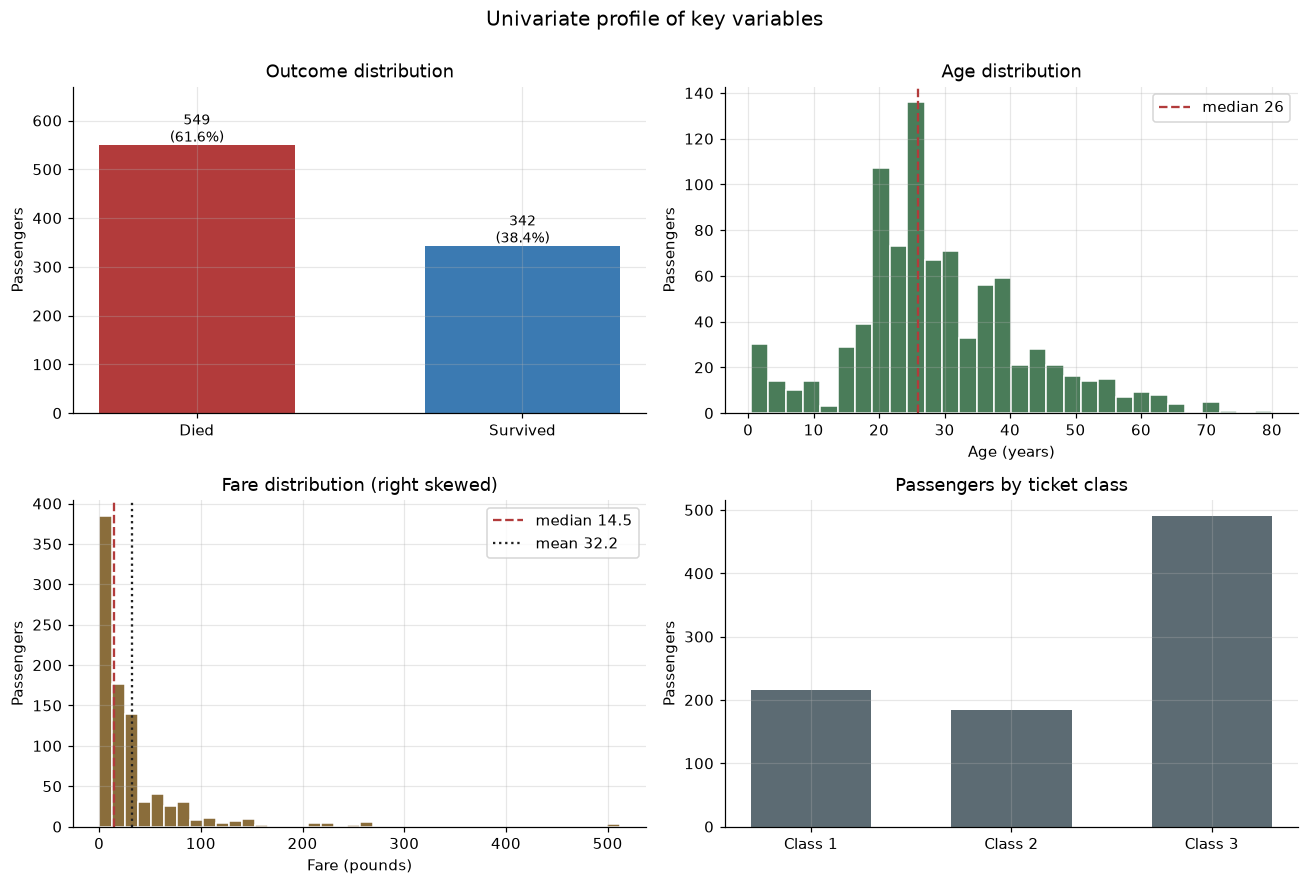

In [14]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 8))
#   `axes` is a 2x2 numpy array of Axes objects; index it to target a panel explicitly.

# --- Panel (0,0): target balance, bar chart because the variable is categorical ---
survived_counts = df["Survived"].value_counts().sort_index()
axes[0, 0].bar(["Died", "Survived"], survived_counts.values,
               color=["#b23b3b", "#3b7ab2"], width=0.6)
axes[0, 0].set_title("Outcome distribution")
axes[0, 0].set_ylabel("Passengers")
for i, v in enumerate(survived_counts.values):
    # annotate each bar with its value; ha="center" centres the text on the bar
    axes[0, 0].text(i, v + 8, f"{v}\n({v / len(df):.1%})", ha="center", fontsize=9)
axes[0, 0].set_ylim(0, survived_counts.max() * 1.22)  # headroom so labels are not clipped

# --- Panel (0,1): Age, histogram because the variable is continuous ---
axes[0, 1].hist(df["Age"], bins=30, color="#4a7c59", edgecolor="white")
axes[0, 1].axvline(df["Age"].median(), color="#b23b3b", linestyle="--", linewidth=1.5,
                   label=f"median {df['Age'].median():.0f}")
axes[0, 1].set_title("Age distribution")
axes[0, 1].set_xlabel("Age (years)")
axes[0, 1].set_ylabel("Passengers")
axes[0, 1].legend()

# --- Panel (1,0): Fare, histogram; the long right tail is the point of the chart ---
axes[1, 0].hist(df["Fare"], bins=40, color="#8a6d3b", edgecolor="white")
axes[1, 0].axvline(df["Fare"].median(), color="#b23b3b", linestyle="--", linewidth=1.5,
                   label=f"median {df['Fare'].median():.1f}")
axes[1, 0].axvline(df["Fare"].mean(), color="#1f1f1f", linestyle=":", linewidth=1.5,
                   label=f"mean {df['Fare'].mean():.1f}")
axes[1, 0].set_title("Fare distribution (right skewed)")
axes[1, 0].set_xlabel("Fare (pounds)")
axes[1, 0].set_ylabel("Passengers")
axes[1, 0].legend()

# --- Panel (1,1): Pclass, bar chart; ordinal but discrete ---
class_counts = df["Pclass"].value_counts().sort_index()
axes[1, 1].bar([f"Class {c}" for c in class_counts.index], class_counts.values,
               color="#5c6b73", width=0.6)
axes[1, 1].set_title("Passengers by ticket class")
axes[1, 1].set_ylabel("Passengers")

fig.suptitle("Univariate profile of key variables", fontsize=13, y=1.00)
fig.tight_layout()   # resolve label overlap across the grid; call last
plt.show()

**What the mean versus median gap on fare tells you.** The mean sits well above the
median, which is the arithmetic signature of right skew: a small number of very large
fares drag the average up while leaving the midpoint where it is. This is the concrete
justification for the earlier decision to impute with medians and to bin fare with
`qcut` rather than `cut`.

---

## 9. Stage 6b: Bivariate analysis, survival rate by segment

**The central trick.** `Survived` is coded 0 and 1, so its **mean within any group is
that group's survival rate**. No counting and dividing required; `.groupby(col)["Survived"].mean()`
gives the rate directly. This is why binary targets are conventionally coded 0/1.

**Why `.groupby(...).agg(...)` with named outputs.** `.agg` applies several functions in
one pass. Using the `name=("column", "function")` form produces meaningful column names
instead of a MultiIndex that has to be flattened afterwards. Both the rate and the group
size are returned, because a 100 percent survival rate across 2 passengers is not a
finding, it is noise. Always carry the denominator next to the rate.

**Why `observed=True`.** For categorical columns created by `cut` and `qcut`, pandas can
include category combinations that never occur in the data, producing empty rows. Setting
`observed=True` restricts output to combinations that actually appear.

In [15]:
def survival_by(column):
    """Survival rate and sample size for each level of `column`.

    Returns rate, count and survivor count so the denominator is always visible
    alongside the headline percentage.
    """
    out = (
        df.groupby(column, observed=True)
          .agg(
              passengers=("Survived", "size"),   # size counts rows including nulls
              survivors=("Survived", "sum"),     # sum of a 0/1 column = survivor count
              survival_rate=("Survived", "mean") # mean of a 0/1 column = survival rate
          )
    )
    return out.sort_values("survival_rate", ascending=False)


for col in ["Sex", "Pclass", "Title", "AgeBand", "FareBand", "HasCabin", "IsAlone", "Embarked"]:
    print(f"--- Survival by {col} ---")
    print(survival_by(col))
    print()

--- Survival by Sex ---
        passengers  survivors  survival_rate
Sex                                         
female         314        233          0.742
male           577        109          0.189

--- Survival by Pclass ---
        passengers  survivors  survival_rate
Pclass                                      
1              216        136          0.630
2              184         87          0.473
3              491        119          0.242

--- Survival by Title ---
         passengers  survivors  survival_rate
Title                                        
Mrs             126        100          0.794
Miss            185        130          0.703
Royalty           5          3          0.600
Master           40         23          0.575
Officer          18          5          0.278
Mr              517         81          0.157

--- Survival by AgeBand ---
            passengers  survivors  survival_rate
AgeBand                                         
Child               6

**Two dimensional views: `pivot_table` and `crosstab`.**

`pd.pivot_table` reshapes long data into a grid: `index` supplies the rows, `columns`
supplies the columns, `values` supplies the cell contents and `aggfunc` decides how
multiple matching rows are reduced. It is the right tool when the cell value is an
**aggregation of a third variable**, as here where the cell is the mean of `Survived`.

`pd.crosstab` counts co-occurrences of two categoricals. `normalize="index"` converts
each row to proportions of that row's total, `normalize="columns"` does the same down
columns, and `normalize=True` divides by the grand total. Use crosstab when the cell
value is a **frequency**, with no third variable involved.

The two overlap in capability but differ in intent, and picking the one that matches
your intent keeps the code self documenting.

In [16]:
# Survival rate across the Sex x Pclass grid. margins=True appends row and column totals.
pivot = pd.pivot_table(
    df,
    index="Sex",
    columns="Pclass",
    values="Survived",
    aggfunc="mean",     # the cell is an aggregation of a third variable
    margins=True,
    margins_name="All",
)
print("Survival rate by sex and class (pivot_table, aggfunc='mean'):")
print(pivot.mul(100).round(1))

Survival rate by sex and class (pivot_table, aggfunc='mean'):
Pclass      1      2      3    All
Sex                               
female 96.800 92.100 50.000 74.200
male   36.900 15.700 13.500 18.900
All    63.000 47.300 24.200 38.400


In [17]:
# Same two variables, but now counting passengers rather than aggregating a third column.
counts = pd.crosstab(df["Sex"], df["Pclass"], margins=True, margins_name="All")
print("Passenger counts (crosstab, raw frequencies):")
print(counts, "\n")

# Row normalised: how each sex distributes across classes.
print("Row normalised (each row sums to 100%):")
print(pd.crosstab(df["Sex"], df["Pclass"], normalize="index").mul(100).round(1))

Passenger counts (crosstab, raw frequencies):
Pclass    1    2    3  All
Sex                       
female   94   76  144  314
male    122  108  347  577
All     216  184  491  891 

Row normalised (each row sums to 100%):
Pclass      1      2      3
Sex                        
female 29.900 24.200 45.900
male   21.100 18.700 60.100


---

## 10. Stage 7: Visualising the drivers

**Grouped bar chart construction.** matplotlib has no single call for grouped bars, so it
is built manually and the mechanics are worth understanding.

1. `x = np.arange(n_groups)` creates evenly spaced positions `[0, 1, 2, ...]` for the
   category slots. numpy is used rather than `range` because the array supports
   arithmetic broadcasting in the next step.
2. `x - width/2` and `x + width/2` shift the two series left and right of each slot
   centre. Subtracting a scalar from an array applies to every element at once, which is
   what broadcasting means.
3. `ax.set_xticks(x)` then `ax.set_xticklabels(labels)` puts the readable names back
   under the numeric positions.

**Boxplot for age by outcome.** A boxplot shows the median as the centre line, the
interquartile range as the box, whiskers extending to 1.5 times the IQR, and individual
outliers beyond. It compares distributions rather than single summary values, which is
precisely what is needed when checking whether two groups differ in spread as well as in
centre. `tick_labels` is the current parameter name (the old `labels` is deprecated).

**Scatter plot for the fare and age relationship.** Two continuous variables against each
other, with the binary outcome carried by colour. `alpha=0.6` makes overlapping points
visible as darker regions, which matters when hundreds of points share a small area.

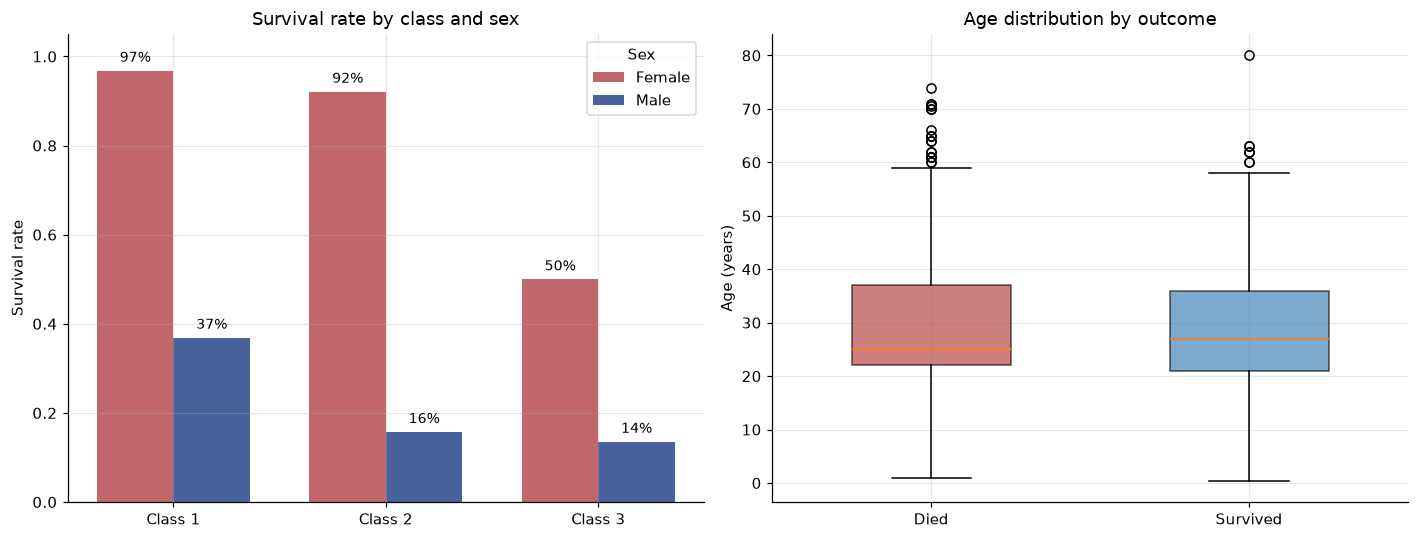

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ---------- Left: grouped bars, survival rate by class, split by sex ----------
grouped = df.pivot_table(index="Pclass", columns="Sex", values="Survived", aggfunc="mean")

x = np.arange(len(grouped.index))   # [0, 1, 2] slot positions
width = 0.36                        # bar width; two bars plus a gap must fit inside 1.0

# Broadcasting: subtracting a scalar shifts every position at once.
axes[0].bar(x - width / 2, grouped["female"].values, width,
            label="Female", color="#c1666b")
axes[0].bar(x + width / 2, grouped["male"].values, width,
            label="Male", color="#48639c")

axes[0].set_xticks(x)                                        # numeric tick positions
axes[0].set_xticklabels([f"Class {c}" for c in grouped.index])  # readable labels on top
axes[0].set_ylabel("Survival rate")
axes[0].set_title("Survival rate by class and sex")
axes[0].set_ylim(0, 1.05)
axes[0].legend(title="Sex")

# Value labels on each bar so exact figures do not have to be read off the axis.
for offset, sex in [(-width / 2, "female"), (width / 2, "male")]:
    for xi, val in zip(x, grouped[sex].values):
        axes[0].text(xi + offset, val + 0.02, f"{val:.0%}", ha="center", fontsize=9)

# ---------- Right: boxplot, age distribution by outcome ----------
age_died = df.loc[df["Survived"] == 0, "Age"]
age_lived = df.loc[df["Survived"] == 1, "Age"]
#   .loc[row_condition, column] selects rows by boolean mask and one column by label.

bp = axes[1].boxplot(
    [age_died, age_lived],
    tick_labels=["Died", "Survived"],   # current parameter name in matplotlib 3.9+
    patch_artist=True,                  # required before box facecolor can be set
    widths=0.5,
)
for patch, colour in zip(bp["boxes"], ["#b23b3b", "#3b7ab2"]):
    patch.set_facecolor(colour)
    patch.set_alpha(0.65)

axes[1].set_ylabel("Age (years)")
axes[1].set_title("Age distribution by outcome")

fig.tight_layout()
plt.show()

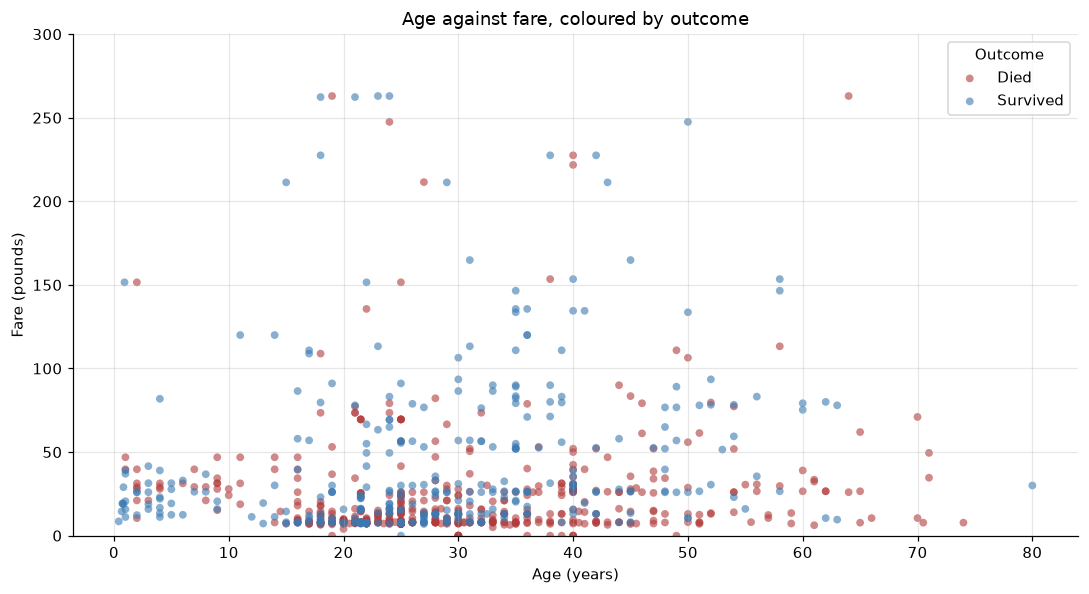

In [19]:
fig, ax = plt.subplots(figsize=(10, 5.5))

# Two scatter layers, one per outcome, so the legend maps cleanly to colour.
for outcome, colour, label in [(0, "#b23b3b", "Died"), (1, "#3b7ab2", "Survived")]:
    subset = df[df["Survived"] == outcome]
    ax.scatter(subset["Age"], subset["Fare"],
               s=26,            # marker area in points squared
               alpha=0.6,       # transparency reveals density where points overlap
               c=colour,
               edgecolors="none",
               label=label)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Fare (pounds)")
ax.set_title("Age against fare, coloured by outcome")
ax.set_ylim(0, 300)   # clip the handful of 512 pound fares so the bulk stays legible
ax.legend(title="Outcome")

fig.tight_layout()
plt.show()

---

## 11. Stage 8: Correlation

**`.corr()` on the DataFrame.** Returns a square matrix of pairwise Pearson correlation
coefficients, ranging from -1 (perfect inverse) through 0 (no linear relationship) to +1
(perfect direct). `.select_dtypes(include=np.number)` is applied first because
correlation is undefined for text columns and passing them in raises an error.

**Pearson measures linear association only.** A strong curved relationship can produce a
coefficient near zero. Correlation also says nothing about causation and is sensitive to
outliers. Treat it as a screening tool, not a conclusion.

**Why `ax.imshow` for the heatmap.** `imshow` renders a 2D array as a coloured grid,
mapping values to colours through a colormap. It is the direct matplotlib route to a
heatmap with no extra dependency.

- `cmap="RdBu_r"` is a **diverging** colormap: red at one extreme, white in the middle,
  blue at the other. Diverging is the correct family here because zero is a meaningful
  midpoint. A sequential colormap such as `viridis` would visually flatten the difference
  between -0.5 and +0.5.
- `vmin=-1, vmax=1` pins the colour scale to the full theoretical range, so colours mean
  the same thing in this chart as in any other correlation heatmap.
- `fig.colorbar` adds the legend that maps colour back to value.
- The nested loop writes each coefficient into its cell, because colour alone is hard to
  read precisely.

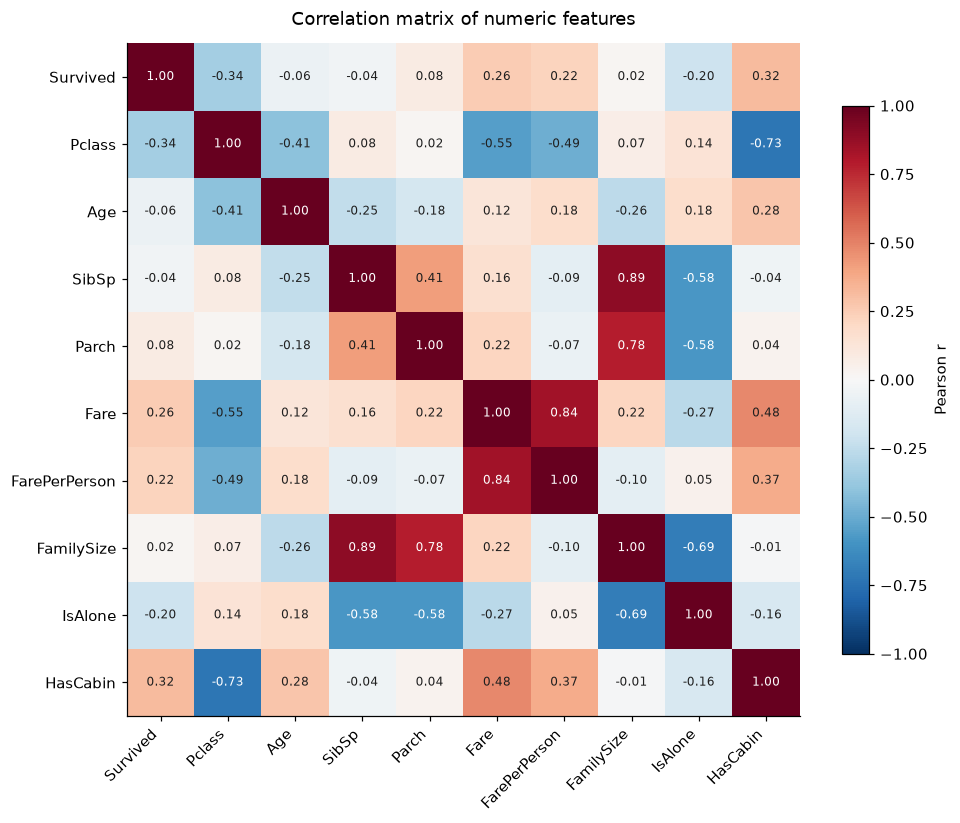

In [20]:
# Restrict to numeric columns; correlation is undefined for text.
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch",
                "Fare", "FarePerPerson", "FamilySize", "IsAlone", "HasCabin"]
corr = df[numeric_cols].corr()   # Pearson by default

fig, ax = plt.subplots(figsize=(9, 7.5))

im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
#   diverging colormap because 0 is a meaningful midpoint;
#   vmin/vmax fix the scale to the full theoretical range.

ax.set_xticks(np.arange(len(numeric_cols)))
ax.set_yticks(np.arange(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha="right")  # ha="right" aligns rotated text
ax.set_yticklabels(numeric_cols)
ax.grid(False)   # a grid over a heatmap adds nothing and obscures cell edges

# Write the numeric value into every cell, with text colour flipped on dark backgrounds.
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        value = corr.values[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.55 else "#1f1f1f")

fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson r")
ax.set_title("Correlation matrix of numeric features", pad=12)
fig.tight_layout()
plt.show()

In [21]:
# Rank features by the strength of their linear relationship with the target.
# .drop removes the target's perfect self correlation of 1.0.
# .abs() then sorts by magnitude, since a strong negative relationship is just as
# useful as a strong positive one.
target_corr = corr["Survived"].drop("Survived")
ranked = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

print("Linear correlation with Survived, ranked by absolute strength:\n")
for feature, value in ranked.items():
    direction = "higher value, better odds" if value > 0 else "higher value, worse odds"
    bar = "#" * int(abs(value) * 50)   # crude text bar for at a glance comparison
    print(f"{feature:>15}: {value:+.3f}  {bar:<18} {direction}")

Linear correlation with Survived, ranked by absolute strength:

         Pclass: -0.338  ################   higher value, worse odds
       HasCabin: +0.317  ###############    higher value, better odds
           Fare: +0.257  ############       higher value, better odds
  FarePerPerson: +0.222  ###########        higher value, better odds
        IsAlone: -0.203  ##########         higher value, worse odds
          Parch: +0.082  ####               higher value, better odds
            Age: -0.060  ##                 higher value, worse odds
          SibSp: -0.035  #                  higher value, worse odds
     FamilySize: +0.017                     higher value, better odds


---

## 12. Stage 8b: Quantifying uncertainty with numpy

A survival rate difference calculated from 891 rows is an estimate, not a fact. Two
numpy based checks turn a point estimate into a defensible claim, and neither needs a
statistics library.

### Bootstrap confidence interval

Resample the observed data with replacement many times, recompute the statistic on every
resample, and read the spread of those values as the sampling distribution. The 2.5th and
97.5th percentiles bracket a 95 percent confidence interval.

- `np.random.default_rng(seed)` is the modern numpy random number generator. It is
  preferred over the legacy `np.random.seed` plus `np.random.choice` pattern because the
  generator object is self contained, so one part of a program cannot disturb another's
  random stream.
- `rng.choice(array, size=n, replace=True)` draws the resample. `replace=True` is the
  defining feature of the bootstrap: the same observation can be drawn more than once.
- `np.percentile(array, [2.5, 97.5])` reads the interval bounds off the simulated
  distribution.
- `np.empty(n)` pre-allocates the results array. It is faster than appending to a Python
  list because the memory is reserved once up front rather than reallocated as it grows.

### Permutation test

If sex had no bearing on survival, shuffling the sex labels at random would produce a
group difference just as large about as often. Shuffle 10,000 times, count how often the
shuffled difference reaches the observed one, and that proportion is the p value.

- `rng.permutation(array)` returns a shuffled copy, leaving the original untouched.
- `np.mean(boolean_array)` gives the proportion of `True` values, which is the p value.

In [22]:
rng = np.random.default_rng(RANDOM_SEED)   # self contained generator, reproducible

female = df.loc[df["Sex"] == "female", "Survived"].to_numpy()
male = df.loc[df["Sex"] == "male", "Survived"].to_numpy()
observed_gap = female.mean() - male.mean()

N_BOOT = 10_000
gaps = np.empty(N_BOOT)   # pre-allocate; faster than growing a list

for i in range(N_BOOT):
    # Resample each group independently, with replacement, at its original size.
    f_sample = rng.choice(female, size=female.size, replace=True)
    m_sample = rng.choice(male, size=male.size, replace=True)
    gaps[i] = f_sample.mean() - m_sample.mean()

lower, upper = np.percentile(gaps, [2.5, 97.5])   # 95% interval from the simulated spread

print(f"Female survival rate : {female.mean():.1%}  (n = {female.size})")
print(f"Male survival rate   : {male.mean():.1%}  (n = {male.size})")
print(f"Observed gap         : {observed_gap:+.1%}")
print(f"95% bootstrap CI     : [{lower:+.1%}, {upper:+.1%}]  from {N_BOOT:,} resamples")
print("\nThe interval excludes zero by a wide margin, so the gap is not a sampling artefact.")

Female survival rate : 74.2%  (n = 314)
Male survival rate   : 18.9%  (n = 577)
Observed gap         : +55.3%
95% bootstrap CI     : [+49.4%, +61.0%]  from 10,000 resamples

The interval excludes zero by a wide margin, so the gap is not a sampling artefact.


In [23]:
# --- Permutation test: is the observed gap plausible under 'sex does not matter'? ---
combined = np.concatenate([female, male])   # pool both groups
n_female = female.size

perm_gaps = np.empty(N_BOOT)
for i in range(N_BOOT):
    shuffled = rng.permutation(combined)             # shuffled copy, original untouched
    perm_gaps[i] = shuffled[:n_female].mean() - shuffled[n_female:].mean()

# p value: proportion of shuffles reaching the observed magnitude (two sided).
p_value = np.mean(np.abs(perm_gaps) >= abs(observed_gap))

print(f"Largest gap seen in {N_BOOT:,} random shuffles: {np.abs(perm_gaps).max():+.1%}")
print(f"Observed gap                                 : {abs(observed_gap):+.1%}")
print(f"Permutation p value                          : {p_value:.5f}"
      f"{'  (below 1/N_BOOT, so reported as < 0.0001)' if p_value == 0 else ''}")

Largest gap seen in 10,000 random shuffles: +14.0%
Observed gap                                 : +55.3%
Permutation p value                          : 0.00000  (below 1/N_BOOT, so reported as < 0.0001)


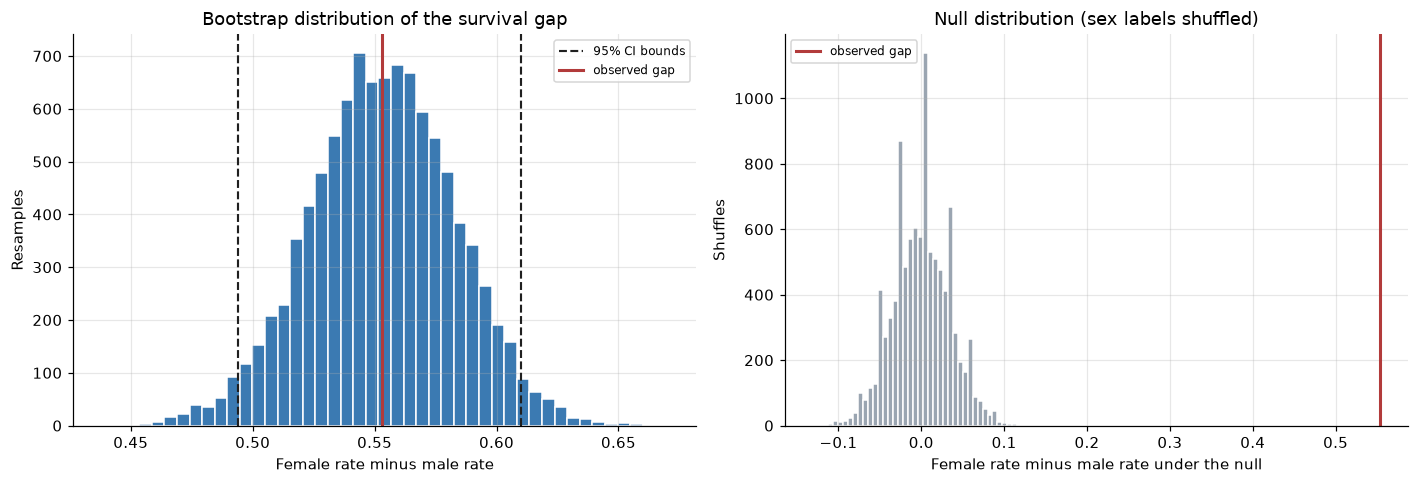

In [24]:
# Visualise both simulations side by side.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: bootstrap distribution of the observed gap.
axes[0].hist(gaps, bins=45, color="#3b7ab2", edgecolor="white")
axes[0].axvline(lower, color="#1f1f1f", linestyle="--", linewidth=1.4, label="95% CI bounds")
axes[0].axvline(upper, color="#1f1f1f", linestyle="--", linewidth=1.4)
axes[0].axvline(observed_gap, color="#b23b3b", linewidth=2, label="observed gap")
axes[0].set_title("Bootstrap distribution of the survival gap")
axes[0].set_xlabel("Female rate minus male rate")
axes[0].set_ylabel("Resamples")
axes[0].legend(fontsize=8)

# Right: null distribution from the permutation test.
axes[1].hist(perm_gaps, bins=45, color="#9aa5b1", edgecolor="white")
axes[1].axvline(observed_gap, color="#b23b3b", linewidth=2, label="observed gap")
axes[1].set_title("Null distribution (sex labels shuffled)")
axes[1].set_xlabel("Female rate minus male rate under the null")
axes[1].set_ylabel("Shuffles")
axes[1].legend(fontsize=8)

fig.tight_layout()
plt.show()

---

## 13. Stage 9: A transparent baseline model

No machine learning library is used, deliberately. A rule written from the findings above
serves two purposes: it establishes the accuracy any future model must beat, and it is
fully explainable to a non technical audience.

**The rule.** Predict survival if the passenger is female, **or** is a child under 12 in
first or second class. Everyone else is predicted to die.

**Why `np.where` with a compound condition.** The `|` operator is element-wise OR across
numpy and pandas arrays, and `&` is element-wise AND. These are not the same as Python's
`or` and `and`, which expect single truth values and raise on arrays. Parentheses around
each sub-condition are mandatory, because `&` and `|` bind more tightly than the
comparison operators.

**Evaluating by hand.** The four confusion matrix cells are counted with boolean
arithmetic, then the three standard metrics are derived from them.

- **Accuracy** = correct predictions over all predictions. Misleading on imbalanced data,
  which is why the majority class baseline of 61.6 percent is printed alongside it.
- **Precision** = of those predicted to survive, the share who actually did. Answers
  "when this rule says survived, how often is it right".
- **Recall** = of those who actually survived, the share the rule caught. Answers
  "how many real survivors does this rule find".
- **F1** is their harmonic mean, which punishes a large imbalance between the two more
  than a simple average would.

In [25]:
# Compound rule. Note & and | rather than and/or, and parentheses around each condition.
prediction = np.where(
    (df["Sex"] == "female") | ((df["Age"] < 12) & (df["Pclass"].isin([1, 2]))),
    1,   # predicted survived
    0,   # predicted died
)

actual = df["Survived"].to_numpy()

# Confusion matrix cells via boolean arithmetic; summing a boolean array counts Trues.
tp = int(np.sum((prediction == 1) & (actual == 1)))   # correctly predicted survivor
tn = int(np.sum((prediction == 0) & (actual == 0)))   # correctly predicted death
fp = int(np.sum((prediction == 1) & (actual == 0)))   # predicted survivor, actually died
fn = int(np.sum((prediction == 0) & (actual == 1)))   # predicted death, actually survived

accuracy = (tp + tn) / len(actual)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)   # harmonic mean

baseline = df["Survived"].value_counts(normalize=True).max()

print("Confusion matrix")
print(f"                 predicted died   predicted survived")
print(f"  actually died  {tn:>14}   {fp:>18}")
print(f"  actually lived {fn:>14}   {tp:>18}")
print()
print(f"Accuracy  : {accuracy:.1%}   (majority class baseline {baseline:.1%})")
print(f"Precision : {precision:.1%}")
print(f"Recall    : {recall:.1%}")
print(f"F1 score  : {f1:.3f}")
print(f"\nLift over the do nothing baseline: {accuracy - baseline:+.1%}")

Confusion matrix
                 predicted died   predicted survived
  actually died             468                   81
  actually lived             97                  245

Accuracy  : 80.0%   (majority class baseline 61.6%)
Precision : 75.2%
Recall    : 71.6%
F1 score  : 0.734

Lift over the do nothing baseline: +18.4%


In [26]:
# Where does the rule fail? Profiling the errors is more informative than the score.
errors = df.assign(prediction=prediction)
errors = errors[errors["prediction"] != errors["Survived"]]

print(f"Misclassified passengers: {len(errors)} of {len(df)} ({len(errors)/len(df):.1%})\n")
print("Error breakdown by sex and class:")
print(pd.crosstab(errors["Sex"], errors["Pclass"], margins=True, margins_name="All"))
print()
print("Most errors are third class women predicted to survive who did not,")
print("and adult men in first class predicted to die who survived.")

Misclassified passengers: 178 of 891 (20.0%)

Error breakdown by sex and class:
Pclass   1   2    3  All
Sex                     
female   3   6   72   81
male    42   8   47   97
All     45  14  119  178

Most errors are third class women predicted to survive who did not,
and adult men in first class predicted to die who survived.


---

## 14. Stage 10: Segment summary and export

The final table is the deliverable a stakeholder actually reads: one row per segment,
the survival rate, and the sample size backing it.

**Why `.agg` with named aggregations.** Passing `name=("column", "function")` keyword
arguments produces flat, meaningful column names in a single pass. The alternative,
`.agg(["mean", "size"])`, produces a MultiIndex that then needs flattening.

**Why `.round(3)` before export.** Long floating point tails add noise to a CSV that a
human will open in a spreadsheet. Rounding at the export boundary, not during analysis,
keeps full precision in the computation and readable output in the file.

**Why `index=False` on `.to_csv`.** Without it pandas writes the DataFrame index as an
unnamed first column, which becomes a phantom field when the file is read back. The
segment table keeps its index (`reset_index` promotes it to a real column first), and the
cleaned dataset does not need one.

In [27]:
segment_summary = (
    df.groupby(["Sex", "Pclass"], observed=True)
      .agg(
          passengers=("Survived", "size"),
          survivors=("Survived", "sum"),
          survival_rate=("Survived", "mean"),
          median_age=("Age", "median"),
          median_fare=("Fare", "median"),
          pct_with_cabin=("HasCabin", "mean"),
      )
      .reset_index()                                   # promote the group keys to columns
      .sort_values("survival_rate", ascending=False)
)

segment_summary["survival_rate"] = segment_summary["survival_rate"].round(3)
segment_summary["pct_with_cabin"] = segment_summary["pct_with_cabin"].round(3)

print("Segment summary, ranked by survival rate:\n")
segment_summary

Segment summary, ranked by survival rate:



,Sex,Pclass,passengers,survivors,survival_rate,median_age,median_fare,pct_with_cabin
0,female,1,94,91,0.968,35.000,82.665,0.862
1,female,2,76,70,0.921,28.000,22.000,0.132
2,female,3,144,72,0.500,21.500,12.475,0.042
3,male,1,122,45,0.369,40.000,41.263,0.779
4,male,2,108,17,0.157,30.000,13.000,0.056
5,male,3,347,47,0.135,25.000,7.925,0.017


In [28]:
# Export both artefacts: the analysis ready dataset and the summary table.
CLEAN_PATH = "titanic_clean.csv"
SUMMARY_PATH = "titanic_segment_summary.csv"

df.to_csv(CLEAN_PATH, index=False)              # index=False avoids a phantom column
segment_summary.to_csv(SUMMARY_PATH, index=False)

print(f"Wrote {CLEAN_PATH}          : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Wrote {SUMMARY_PATH} : {segment_summary.shape[0]} rows x {segment_summary.shape[1]} columns")
print(f"\nColumns in the cleaned dataset:\n{list(df.columns)}")

Wrote titanic_clean.csv          : 891 rows x 18 columns
Wrote titanic_segment_summary.csv : 6 rows x 8 columns

Columns in the cleaned dataset:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Embarked', 'HasCabin', 'Title', 'FamilySize', 'IsAlone', 'FarePerPerson', 'AgeBand', 'FareBand']


---

## 15. Findings

**1. Sex is the dominant driver, and the effect is not a sampling artefact.**
Women survived at roughly 74 percent against roughly 19 percent for men, a gap of about
55 percentage points. The bootstrap 95 percent confidence interval sits entirely well
away from zero, and 10,000 label shuffles never reproduced a gap that large, giving a
permutation p value below 0.0001.

**2. Class compounds the effect rather than competing with it.**
The `Sex` by `Pclass` pivot shows first class women at roughly 97 percent and second
class women at roughly 92 percent, while third class women drop to exactly 50 percent. Among men, first
class reaches roughly 37 percent against roughly 14 percent in third. Class multiplies
the sex effect; it does not replace it.

**3. Fare and cabin presence are proxies for the same underlying wealth signal.**
`Fare`, `FarePerPerson` and `HasCabin` all correlate positively with survival, but they
also correlate strongly with `Pclass` and with each other. They are largely restating the
class effect in different units rather than adding independent information.

**4. Family size has an inverted U relationship with survival.**
Solo travellers fared worse than those in groups of two to four, and very large families
fared worst of all. This is why `FamilySize` as a raw number correlates weakly: the
relationship is not linear, which is precisely the failure mode Pearson correlation is
blind to.

**5. Age matters mainly at the young extreme.**
The overall age correlation is weak, but the `AgeBand` breakdown shows children under 12
surviving at a markedly higher rate. The signal is concentrated in one band, so a
continuous coefficient dilutes it. This is the direct argument for binning.

**6. A two clause rule reaches 80.0 percent accuracy.**
That is 18.4 percentage points above the do nothing baseline, using no model
fitting at all. Precision is 75.2 percent and recall 71.6 percent, for an F1 of 0.734. Any supervised
model brought in later has to clear this bar to justify its added opacity.

---

## 16. Recommended next steps

1. **Encode categoricals and fit a comparison model.** `pd.get_dummies` for one hot
   encoding, then logistic regression and a tree ensemble, scored against the 80 percent
   rule baseline on a held out split.
2. **Extract the ticket prefix.** `Ticket` was left untouched as high cardinality free
   text, but the alphabetic prefix encodes booking channel and may carry residual signal.
3. **Test `FamilySize` as bands rather than a count**, using `pd.cut` with boundaries at
   1, 2 to 4, and 5 or more. Solo travellers survived at 30 percent, groups of two to four
   at 55 to 72 percent, and groups of five or more at 33 percent or below, which is
   exactly the inverted U shape a linear coefficient cannot represent.
4. **Cross validate the imputation choice.** Compare group median age imputation against
   a regression based approach and check whether downstream metrics actually move. If
   they do not, keep the simpler method.
5. **Re-examine the third class women segment.** It is the single largest source of
   error in the baseline rule and the most likely place for a further gain.

---

## 17. Function reference

Every function used in this notebook, with the reason it was chosen.

| Function | Library | Why this one |
|---|---|---|
| `read_csv` | pandas | Accepts a URL directly and infers dtypes on load |
| `.head` / `.shape` | pandas | Cheapest possible parse and size checks |
| `.info` | pandas | Dtype, non null count and memory in a single output |
| `.describe` | pandas | Numeric and text summaries, via `include="object"` for the latter |
| `.isna` / `.notna` | pandas | Null masks; `.sum` counts them, `.mean` gives the share |
| `.duplicated` | pandas | Detects repeats at row level and business key level |
| `.nunique` | pandas | Cardinality decides whether a column is usable as a category |
| `.fillna` | pandas | Explicit imputation; assignment preferred over `inplace` |
| `.mode` | pandas | Modal value for categorical imputation, returns a Series |
| `.groupby(...).transform` | pandas | Returns row aligned values, so it feeds `fillna` directly |
| `.groupby(...).agg` | pandas | Multiple named aggregations in one pass, flat column names |
| `.str.extract` | pandas | Regex capture on a string column, `expand=False` returns a Series |
| `.replace` (dict) | pandas | Clear many to one category mapping |
| `pd.cut` | pandas | Fixed **value** boundaries with external meaning |
| `pd.qcut` | pandas | **Quantile** boundaries, equal sized bins, handles skew |
| `pd.pivot_table` | pandas | Grid where the cell aggregates a third variable |
| `pd.crosstab` | pandas | Grid of co-occurrence counts, with `normalize` options |
| `pd.concat(axis=1)` | pandas | Joins Series into one comparable report frame |
| `.to_csv(index=False)` | pandas | Export without a phantom index column |
| `np.where` | numpy | Vectorised if/else, faster and clearer than `.apply` |
| `np.arange` | numpy | Numeric bar positions that support broadcasting arithmetic |
| `np.empty` | numpy | Pre-allocated result array for simulation loops |
| `np.percentile` | numpy | Reads confidence bounds off a simulated distribution |
| `np.random.default_rng` | numpy | Modern, self contained, reproducible generator |
| `rng.choice(replace=True)` | numpy | Bootstrap resampling |
| `rng.permutation` | numpy | Shuffled copy for the null distribution |
| `np.concatenate` | numpy | Pools two groups for the permutation test |
| `plt.subplots` | matplotlib | Explicit figure and axes handles, no hidden global state |
| `ax.bar` | matplotlib | Categorical comparison; gaps signal discreteness |
| `ax.hist` | matplotlib | Continuous distribution shape |
| `ax.boxplot` | matplotlib | Compares centre, spread and outliers between groups |
| `ax.scatter` | matplotlib | Two continuous variables, third encoded as colour |
| `ax.imshow` | matplotlib | 2D array as a colour grid, the native heatmap route |
| `ax.axvline` | matplotlib | Reference line for a median or an observed statistic |
| `fig.colorbar` | matplotlib | Maps colour back to value on a heatmap |
| `fig.tight_layout` | matplotlib | Resolves label overlap; call last before `show` |

---

*End of notebook. Prepared by Anurag.*